# Modelos de tópicos: LSA y LDiA sobre datos de salud mental

Basado en el capítulo 4 de *Natural Language Processing in Action* (nlpia2).
Clasificación binaria `Normal` (1) vs `Depression` (0):

1. **TF-IDF + LDA** (Linear Discriminant Analysis) como línea base.
2. **LSA**: TF-IDF → `TruncatedSVD` (16 tópicos) → LDA.
3. **LDiA**: bolsa de palabras → `LatentDirichletAllocation` (16 y 32 tópicos) → LDA.

> Nomenclatura del libro: **LDA** = *Linear Discriminant Analysis* (clasificador),
> **LDiA** = *Latent Dirichlet Allocation* (modelo de tópicos).

Todos los modelos usan el mismo split 80/20 con `random_state=271828`, igual que `modelo_bayes_ingenuo.ipynb`.
Los vectorizadores, el SVD y LDiA se ajustan **solo con train** para evitar fuga de información hacia test.

In [1]:
# En Colab descomentar:
# !pip install -U spacy
# !python -m spacy download es_core_news_sm

In [2]:
import pandas as pd
import numpy as np
import spacy

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import precision_score, recall_score, f1_score

from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation as LDiA

In [3]:
datos_raw = pd.read_csv("datos_salud_mental.csv")

In [4]:
datos_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 31755 entries, 0 to 31754
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   status           31755 non-null  str  
 1   statement_es_es  31755 non-null  str  
dtypes: str(2)
memory usage: 496.3 KB


In [5]:
def create_numeric_status(df):
    df['numeric_status'] = df['status'].apply(lambda x: 1 if x == 'Normal' else 0)
    return df

In [6]:
datos = create_numeric_status(datos_raw.copy())
datos.head()

,status,statement_es_es,numeric_status
0,Normal,Gr gr soñando con el ex crush para que sea mi ...,1
1,Normal,wkwkwk qué broma,1
2,Normal,Las hojas también están de espera frente al PC...,1
3,Normal,Gracias a Dios aunque sea un viaje en coche,1
4,Normal,teaser de boda concepto utilizando la canción ...,1


In [7]:
datos = datos[["statement_es_es", "numeric_status"]]

In [8]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 31755 entries, 0 to 31754
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   statement_es_es  31755 non-null  str  
 1   numeric_status   31755 non-null  int64
dtypes: int64(1), str(1)
memory usage: 496.3 KB


In [9]:
datos["numeric_status"].value_counts()

numeric_status
1    16351
0    15404
Name: count, dtype: int64

## Tokenización con spaCy

Solo necesitamos `token.text`, así que usamos únicamente el tokenizer de spaCy (`nlp.tokenizer`): produce
los mismos tokens que `nlp(...)` pero sin correr el tagger/parser/NER, lo cual es mucho más rápido en
~32 mil documentos. Descartamos tokens de puntuación y espacios.

In [10]:
nlp = spacy.load("es_core_news_sm")

In [11]:
def spacy_tokenize(sentence):
    return [token.text for token in nlp.tokenizer(sentence.lower())
            if not (token.is_punct or token.is_space)]

In [12]:
spacy_tokenize("No puedo más, me siento vacío y cansado todo el tiempo...")

['no',
 'puedo',
 'más',
 'me',
 'siento',
 'vacío',
 'y',
 'cansado',
 'todo',
 'el',
 'tiempo']

## Split train / test

Mismo split que `modelo_bayes_ingenuo.ipynb` (80/20, `random_state=271828`).

In [13]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    datos["statement_es_es"], datos["numeric_status"], test_size=0.2, random_state=271828)
print(X_train_text.shape)
print(X_test_text.shape)
print(y_train.shape)
print(y_test.shape)

(25404,)
(6351,)
(25404,)
(6351,)


## TF-IDF

`min_df=0.1` (10% de los documentos) deja casi sin vocabulario en textos cortos, así que usamos un mínimo
absoluto de 5 documentos y limitamos a las 2000 palabras más frecuentes para que la matriz densa que
requiere LDA quepa en memoria.

In [14]:
tfidf_model = TfidfVectorizer(tokenizer=spacy_tokenize, token_pattern=None, lowercase=False,
                              max_df=0.7, min_df=5, max_features=2000, dtype=np.float32)

In [15]:
tfidf_train = tfidf_model.fit_transform(raw_documents=X_train_text).toarray()
tfidf_test = tfidf_model.transform(X_test_text).toarray()
tfidf_train.shape, tfidf_test.shape

((25404, 2000), (6351, 2000))

In [16]:
terms = tfidf_model.get_feature_names_out()
df_tfidf = pd.DataFrame(tfidf_train[:5], columns=terms)
df_tfidf.loc[:, (df_tfidf > 0).any()]

,18,27,a,abusivo,acuesto,ahora,al,alegría,alrededor,amigos,...,tonto,un,una,vacaciones,veo,vida,videojuegos,vuelva,y,ya
0,0.000000,0.00000,0.090542,0.000000,0.183671,0.000000,0.000000,0.00000,0.130954,0.089193,...,0.000000,0.00000,0.000000,0.152282,0.114079,0.000000,0.152764,0.166479,0.311754,0.079839
1,0.000000,0.12507,0.157841,0.125777,0.000000,0.000000,0.000000,0.10661,0.000000,0.000000,...,0.103194,0.07198,0.039455,0.000000,0.000000,0.049489,0.000000,0.000000,0.124224,0.055673
2,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.00000,0.031425,0.000000,0.000000,0.053163,0.049279,0.00000,0.000000,0.000000,...,0.000000,0.00000,0.117828,0.000000,0.000000,0.000000,0.106041,0.000000,0.092744,0.000000
4,0.120189,0.00000,0.000000,0.000000,0.295418,0.000000,0.000000,0.00000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.057075,0.000000,0.000000,0.143265,0.000000


## Línea base: TF-IDF + LDA

In [17]:
lda_tfidf = LinearDiscriminantAnalysis(n_components=1)

In [18]:
lda = lda_tfidf.fit(tfidf_train, y_train)

In [19]:
round(float(lda.score(tfidf_train, y_train)), 3)

0.949

In [20]:
round(float(lda.score(tfidf_test, y_test)), 3)

0.926

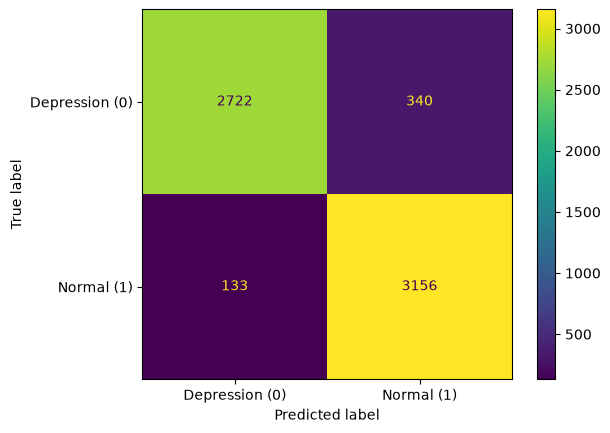

In [21]:
ConfusionMatrixDisplay.from_estimator(lda, tfidf_test, y_test,
                                      display_labels=['Depression (0)', 'Normal (1)'])
plt.show()

In [22]:
hparam_table = pd.DataFrame()

In [23]:
def hparam_rec(model, X_train, y_train, X_test, y_test,
               model_name, features):
  return {
        'classifier': model_name,
        'features': features,
        'train_accuracy': float(model.score(X_train, y_train)),
        'test_accuracy': float(model.score(X_test, y_test)),
        'test_precision':
            precision_score(y_test, model.predict(X_test)),
        'test_recall':
            recall_score(y_test, model.predict(X_test)),
        'test_f1': f1_score(y_test, model.predict(X_test))
        }

In [24]:
tfidf_performance = hparam_rec(lda, tfidf_train, y_train, tfidf_test, y_test, 'LDA', 'TF-IDF (spacy tokenizer)')
hparam_table = pd.concat([hparam_table, pd.DataFrame([tfidf_performance])], ignore_index=True)

In [25]:
hparam_table.T

,0
classifier,LDA
features,TF-IDF (spacy tokenizer)
train_accuracy,0.949378
test_accuracy,0.925524
test_precision,0.902746
test_recall,0.959562
test_f1,0.930287


## LSA: TF-IDF → TruncatedSVD (16 tópicos)

LSA descompone la matriz TF-IDF con SVD truncado; cada tópico es una combinación lineal de palabras
(con pesos positivos y negativos).

In [26]:
svd = TruncatedSVD(n_components=16, n_iter=100, random_state=271828)

In [27]:
columns = ['topic{}'.format(i) for i in range(svd.n_components)]

In [28]:
svd_topic_vectors_train = svd.fit_transform(tfidf_train)
svd_topic_vectors_test = svd.transform(tfidf_test)

In [29]:
svd_topic_vectors_train = pd.DataFrame(svd_topic_vectors_train, columns=columns, index=X_train_text.index)
svd_topic_vectors_test = pd.DataFrame(svd_topic_vectors_test, columns=columns, index=X_test_text.index)

In [30]:
svd_topic_vectors_train.round(3).head(6)

,topic0,topic1,topic2,topic3,topic4,topic5,topic6,topic7,topic8,topic9,topic10,topic11,topic12,topic13,topic14,topic15
15415,0.426,-0.038,-0.021,-0.134,-0.090,-0.046,-0.015,-0.012,0.063,0.003,-0.122,0.011,-0.120,-0.069,-0.050,0.021
13909,0.544,0.063,-0.032,0.032,-0.058,0.049,0.044,-0.027,0.017,0.067,-0.062,0.018,0.012,0.062,-0.034,-0.028
22760,0.074,-0.167,-0.054,-0.020,0.153,0.139,-0.028,-0.001,-0.087,0.095,-0.124,0.388,0.395,-0.281,0.065,-0.160
14511,0.460,-0.092,-0.037,0.068,0.046,0.033,0.138,0.012,-0.010,-0.036,-0.005,0.054,-0.008,-0.031,0.005,0.033
13517,0.467,-0.075,-0.123,-0.012,0.051,-0.126,0.005,0.062,0.110,0.079,-0.037,0.097,0.079,-0.034,-0.019,0.038
25421,0.323,-0.025,-0.039,-0.037,-0.012,-0.062,-0.012,0.043,-0.003,0.035,-0.003,-0.048,0.003,0.077,-0.024,-0.040


In [31]:
topic_term_matrix = pd.DataFrame(svd.components_, columns=terms, index=columns)

In [32]:
pd.options.display.max_columns = 8
topic_term_matrix.sample(5, axis='columns', random_state=271828).head(4)

,ayudar,pecho,empeora,cómodo,hable
topic0,0.007199,0.004094,0.004832,0.002784,0.001776
topic1,0.003730,0.001984,-0.003638,0.000278,-0.003219
topic2,0.001966,-0.000633,-0.002117,-0.000219,-0.002687
topic3,-0.000149,-0.002277,-0.000434,-0.000657,0.000603


### Palabras con mayor peso en cada tópico LSA

In [33]:
def top_terms(topic_term, n=10):
    return pd.DataFrame({topic: row.nlargest(n).index for topic, row in topic_term.iterrows()}).T

In [34]:
pd.options.display.max_columns = 12
top_terms(topic_term_matrix)

,0,1,2,3,4,5,6,7,8,9
topic0,que,y,de,no,a,me,la,en,mi,el
topic1,de,la,el,en,depresión,un,y,a,del,los
topic2,qué,por,es,la,de,te,el,tu,pasa,depresión
topic3,es,que,lo,la,el,te,sí,eso,si,no
topic4,no,de,el,quiero,puedo,estoy,en,nada,tengo,cansado
topic5,a,la,no,te,quiero,voy,depresión,las,ir,de
topic6,de,que,lo,qué,te,acabo,creo,por,antes,las
topic7,el,en,a,que,un,trabajo,está,te,día,no
topic8,la,en,depresión,el,que,no,me,por,está,gente
topic9,me,la,siento,estoy,el,a,tan,quiero,por,mañana


### Tópicos LSA más asociados a cada clase

Diferencia del promedio de cada tópico entre documentos `Normal` y `Depression` (train).

In [35]:
lsa_class_means = svd_topic_vectors_train.groupby(y_train.values).mean().T
lsa_class_means.columns = ['Depression (0)', 'Normal (1)']
lsa_class_means['diferencia'] = lsa_class_means['Normal (1)'] - lsa_class_means['Depression (0)']
lsa_class_means.sort_values('diferencia').round(4)

,Depression (0),Normal (1),diferencia
topic0,0.4154,0.1493,-0.2661
topic14,0.0132,-0.0051,-0.0183
topic11,0.0029,-0.0131,-0.0160
topic8,0.0036,-0.0087,-0.0123
topic12,0.0063,0.0023,-0.0040
topic6,-0.0048,-0.0048,0.0000
topic13,0.0004,0.0033,0.0029
topic10,-0.0062,-0.0018,0.0044
topic9,-0.0014,0.0035,0.0049
topic4,0.0006,0.0059,0.0053


### Clasificación sobre los 16 tópicos LSA

In [36]:
lda_lsa = LinearDiscriminantAnalysis(n_components=1)

In [37]:
lda_lsa_model = lda_lsa.fit(svd_topic_vectors_train, y_train)

In [38]:
round(float(lda_lsa_model.score(svd_topic_vectors_train, y_train)), 3)

0.896

In [39]:
round(float(lda_lsa_model.score(svd_topic_vectors_test, y_test)), 3)

0.895

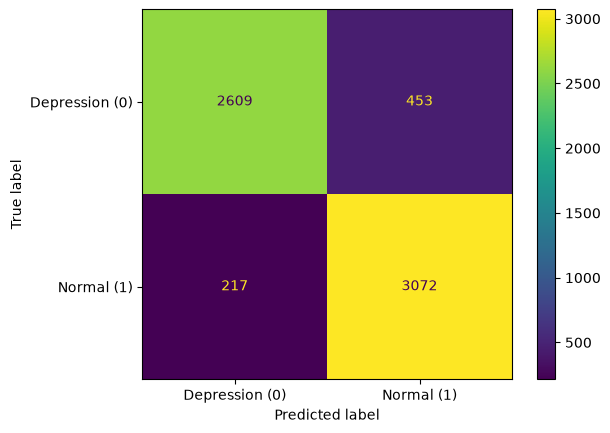

In [40]:
ConfusionMatrixDisplay.from_estimator(lda_lsa_model, svd_topic_vectors_test, y_test,
                                      display_labels=['Depression (0)', 'Normal (1)'])
plt.show()

In [41]:
lsa_performance = hparam_rec(lda_lsa_model, svd_topic_vectors_train, y_train,
                             svd_topic_vectors_test, y_test, 'LDA', 'LSA (16d)')
hparam_table = pd.concat([hparam_table, pd.DataFrame([lsa_performance])], ignore_index=True)

In [42]:
hparam_table.T

,0,1
classifier,LDA,LDA
features,TF-IDF (spacy tokenizer),LSA (16d)
train_accuracy,0.949378,0.895764
test_accuracy,0.925524,0.894505
test_precision,0.902746,0.871489
test_recall,0.959562,0.934022
test_f1,0.930287,0.901673


## LDiA: bolsa de palabras → Latent Dirichlet Allocation

LDiA es un modelo generativo: cada documento es una mezcla de tópicos y cada tópico una distribución
de probabilidad sobre palabras. Trabaja con **conteos** (no TF-IDF), por eso usamos `CountVectorizer`.
Aquí sí quitamos stopwords en español: con conteos crudos dominarían todos los tópicos y no serían
interpretables.

In [43]:
from spacy.lang.es.stop_words import STOP_WORDS

spanish_stopwords = sorted(STOP_WORDS)


def spacy_tokenize_alpha(sentence):
    # Para LDiA solo palabras: descartamos números y símbolos sueltos ($, +, 0...) que ensucian los tópicos
    return [token for token in spacy_tokenize(sentence) if token.isalpha()]


counter = CountVectorizer(tokenizer=spacy_tokenize_alpha, token_pattern=None, lowercase=False,
                          stop_words=spanish_stopwords, max_df=0.7, min_df=5, max_features=5000)

In [44]:
bow_train = counter.fit_transform(X_train_text)
bow_test = counter.transform(X_test_text)
bow_terms = counter.get_feature_names_out()
bow_train.shape, bow_test.shape

((25404, 5000), (6351, 5000))

In [45]:
bow_doc0 = pd.Series(bow_train[0].toarray()[0], index=bow_terms)
print(X_train_text.iloc[0])
bow_doc0[bow_doc0 > 0]

Por favor, dame ideas de qué hacer aparte de eso. Ya no juego a los videojuegos y he estado rechazando las reuniones sociales con amigos así que estoy buscando otras cosas para hacer y espero que me sienta mejor y vuelva a salir y demás. Tomé bajas por enfermedad y vacaciones, pero no ayudaron porque solo cuando estaba completamente sola sentía que me estaba mejorando cuando había familia alrededor me sentía peor. Simplemente me acuesto en la cama y veo películas y duermo todo el día.


acuesto          1
amigos           1
aparte           1
ayudaron         1
bajas            1
buscando         1
cama             1
completamente    1
cosas            1
dame             1
duermo           1
enfermedad       1
espero           1
familia          1
favor            1
ideas            1
juego            1
mejorando        1
películas        1
reuniones        1
salir            1
sentía           2
sienta           1
simplemente      1
sociales         1
tomé             1
vacaciones       1
veo              1
videojuegos      1
vuelva           1
dtype: int64

### LDiA con 16 tópicos

In [46]:
ldia = LDiA(n_components=16, learning_method='online', max_iter=20,
            random_state=271828, n_jobs=-1)
ldia = ldia.fit(bow_train)
ldia.components_.shape

(16, 5000)

In [47]:
ldia_columns = ['topic{}'.format(i) for i in range(ldia.n_components)]
term_topic_matrix = pd.DataFrame(ldia.components_.T, index=bow_terms, columns=ldia_columns)
term_topic_matrix.round(2).head(3)

,topic0,topic1,topic2,topic3,topic4,topic5,...,topic10,topic11,topic12,topic13,topic14,topic15
abajo,0.06,149.71,0.06,0.07,0.06,0.06,...,0.06,0.06,0.06,0.06,0.08,0.06
abandonado,0.06,0.06,0.06,0.06,0.06,0.06,...,0.06,0.06,0.06,0.06,0.06,8.35
abandonar,0.06,0.06,0.06,0.06,15.11,12.82,...,0.06,0.06,0.06,0.06,0.06,0.06


In [48]:
pd.options.display.max_columns = 12
top_terms(term_topic_matrix.T)

,0,1,2,3,4,5,6,7,8,9
topic0,terapeuta,mañana,gracias,semana,pensamientos,debo,pena,seguro,vale,suicidas
topic1,vida,años,padres,trabajo,casa,siento,dinero,año,siquiera,escuela
topic2,alguien,preguntas,respuesta,hombres,película,humor,límite,cambios,recibí,simple
topic3,finalmente,cansado,familia,mantener,hijo,hijos,desearía,esposa,perro,desastre
topic4,favor,has,espero,sociales,juego,jugar,cama,salir,videojuegos,raro
topic5,depresión,ansiedad,alguien,probablemente,sentir,siento,normal,problema,dejar,pensar
topic6,años,amigos,amigo,quería,relación,meses,podía,tuve,hablar,sentía
topic7,quiero,vida,simplemente,siento,realmente,alguien,cosas,gente,morir,amigos
topic8,trabajo,depresión,años,tiempo,ayuda,necesito,terapia,ansiedad,tomar,siento
topic9,siento,simplemente,cosas,siquiera,odio,triste,sentir,feliz,quiero,veo


In [49]:
ldia16_topic_vectors_train = pd.DataFrame(ldia.transform(bow_train), index=X_train_text.index, columns=ldia_columns)
ldia16_topic_vectors_test = pd.DataFrame(ldia.transform(bow_test), index=X_test_text.index, columns=ldia_columns)
ldia16_topic_vectors_train.round(2).head()

,topic0,topic1,topic2,topic3,topic4,topic5,...,topic10,topic11,topic12,topic13,topic14,topic15
15415,0.00,0.00,0.00,0.00,0.74,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00
13909,0.27,0.00,0.00,0.00,0.00,0.48,...,0.00,0.00,0.00,0.00,0.00,0.00
22760,0.03,0.03,0.03,0.03,0.03,0.03,...,0.03,0.03,0.03,0.03,0.03,0.03
14511,0.00,0.03,0.00,0.00,0.05,0.06,...,0.00,0.00,0.00,0.00,0.00,0.00
13517,0.00,0.00,0.00,0.00,0.00,0.03,...,0.00,0.00,0.00,0.00,0.00,0.00


### Tópicos LDiA más asociados a cada clase

Proporción media de cada tópico en documentos `Normal` vs `Depression` (train).

In [50]:
ldia_class_means = ldia16_topic_vectors_train.groupby(y_train.values).mean().T
ldia_class_means.columns = ['Depression (0)', 'Normal (1)']
ldia_class_means['diferencia'] = ldia_class_means['Normal (1)'] - ldia_class_means['Depression (0)']
ldia_class_means['top_terms'] = [', '.join(term_topic_matrix[t].nlargest(6).index) for t in ldia_class_means.index]
ldia_class_means.sort_values('diferencia').round(3)

,Depression (0),Normal (1),diferencia,top_terms
topic7,0.206,0.068,-0.138,"quiero, vida, simplemente, siento, realmente, ..."
topic8,0.113,0.069,-0.044,"trabajo, depresión, años, tiempo, ayuda, necesito"
topic9,0.116,0.073,-0.044,"siento, simplemente, cosas, siquiera, odio, tr..."
topic1,0.106,0.077,-0.029,"vida, años, padres, trabajo, casa, siento"
topic5,0.073,0.047,-0.025,"depresión, ansiedad, alguien, probablemente, s..."
topic14,0.065,0.059,-0.006,"mental, salud, ansiedad, problemas, cuerpo, se..."
topic6,0.069,0.073,0.004,"años, amigos, amigo, quería, relación, meses"
topic15,0.047,0.058,0.011,"personas, gente, mundo, razón, tienes, energía"
topic13,0.033,0.054,0.022,"depresión, cerca, puedes, hermana, piensa, cor..."
topic0,0.033,0.060,0.027,"terapeuta, mañana, gracias, semana, pensamient..."


### Clasificación sobre los 16 tópicos LDiA

In [51]:
model_ldia16 = LinearDiscriminantAnalysis()
model_ldia16 = model_ldia16.fit(ldia16_topic_vectors_train, y_train)
ldia16_performance = hparam_rec(model_ldia16, ldia16_topic_vectors_train, y_train,
                                ldia16_topic_vectors_test, y_test, 'LDA', 'LDiA (16d)')
hparam_table = pd.concat([hparam_table, pd.DataFrame([ldia16_performance])], ignore_index=True)
hparam_table.T

,0,1,2
classifier,LDA,LDA,LDA
features,TF-IDF (spacy tokenizer),LSA (16d),LDiA (16d)
train_accuracy,0.949378,0.895764,0.794402
test_accuracy,0.925524,0.894505,0.796567
test_precision,0.902746,0.871489,0.843481
test_recall,0.959562,0.934022,0.745515
test_f1,0.930287,0.901673,0.791478


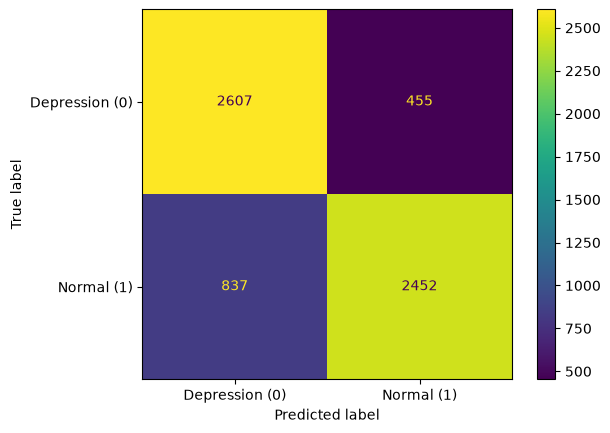

In [52]:
ConfusionMatrixDisplay.from_estimator(model_ldia16, ldia16_topic_vectors_test, y_test,
                                      display_labels=['Depression (0)', 'Normal (1)'])
plt.show()

### LDiA con 32 tópicos

In [53]:
ldia32 = LDiA(n_components=32, learning_method='online', max_iter=20,
              random_state=271828, n_jobs=-1)
ldia32 = ldia32.fit(bow_train)
ldia32_columns = ['topic{}'.format(i) for i in range(ldia32.n_components)]
ldia32_topic_vectors_train = pd.DataFrame(ldia32.transform(bow_train), index=X_train_text.index, columns=ldia32_columns)
ldia32_topic_vectors_test = pd.DataFrame(ldia32.transform(bow_test), index=X_test_text.index, columns=ldia32_columns)

model_ldia32 = LinearDiscriminantAnalysis()
model_ldia32 = model_ldia32.fit(ldia32_topic_vectors_train, y_train)
ldia32_performance = hparam_rec(model_ldia32, ldia32_topic_vectors_train, y_train,
                                ldia32_topic_vectors_test, y_test, 'LDA', 'LDiA (32d)')
hparam_table = pd.concat([hparam_table, pd.DataFrame([ldia32_performance])], ignore_index=True)
hparam_table.T

,0,1,2,3
classifier,LDA,LDA,LDA,LDA
features,TF-IDF (spacy tokenizer),LSA (16d),LDiA (16d),LDiA (32d)
train_accuracy,0.949378,0.895764,0.794402,0.827153
test_accuracy,0.925524,0.894505,0.796567,0.826956
test_precision,0.902746,0.871489,0.843481,0.871186
test_recall,0.959562,0.934022,0.745515,0.781393
test_f1,0.930287,0.901673,0.791478,0.82385


## Comparación final de los tres tipos de modelo

Se agrega el resultado del Bayes ingenuo (`resultados_bayes.csv`, generado por `modelo_bayes_ingenuo.ipynb`
con el mismo split).

In [54]:
import os

comparison = hparam_table.copy()
if os.path.exists("resultados_bayes.csv"):
    comparison = pd.concat([pd.read_csv("resultados_bayes.csv"), comparison], ignore_index=True)
else:
    print("Ejecuta primero modelo_bayes_ingenuo.ipynb para incluir el Bayes ingenuo")
comparison.round(3)

,classifier,features,train_accuracy,test_accuracy,test_precision,test_recall,test_f1
0,Naive Bayes,BoW (TweetTokenizer + stopwords + Snowball ste...,0.866,0.824,0.962,0.687,0.801
1,LDA,TF-IDF (spacy tokenizer),0.949,0.926,0.903,0.960,0.930
2,LDA,LSA (16d),0.896,0.895,0.871,0.934,0.902
3,LDA,LDiA (16d),0.794,0.797,0.843,0.746,0.791
4,LDA,LDiA (32d),0.827,0.827,0.871,0.781,0.824


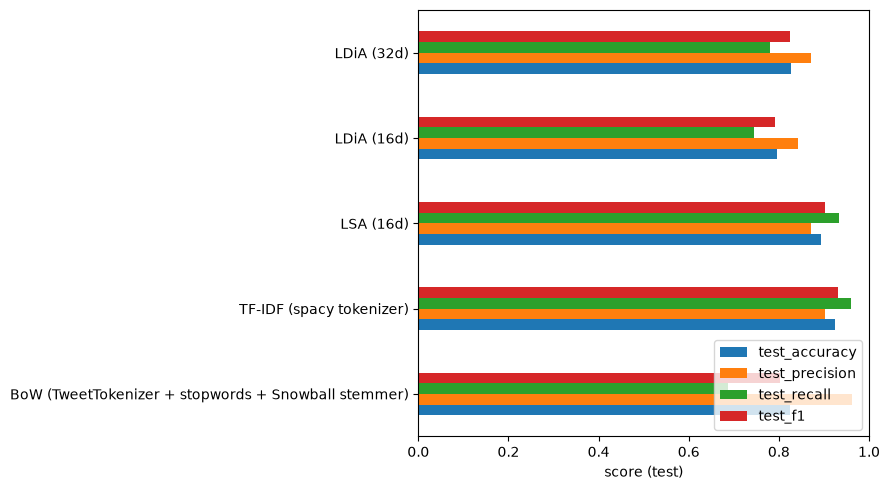

In [55]:
ax = comparison.set_index('features')[['test_accuracy', 'test_precision', 'test_recall', 'test_f1']].plot.barh(figsize=(9, 5))
ax.set_xlim(0, 1)
ax.set_xlabel('score (test)')
ax.set_ylabel('')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Conclusiones

| Modelo | Features | Test accuracy | Test F1 |
|---|---|---|---|
| Naive Bayes | BoW + stemming | 0.824 | 0.801 |
| LDA | TF-IDF (2000 términos) | **0.926** | **0.930** |
| LDA | LSA (16 tópicos) | 0.895 | 0.902 |
| LDA | LDiA (16 tópicos) | 0.797 | 0.791 |
| LDA | LDiA (32 tópicos) | 0.827 | 0.824 |

- **TF-IDF + LDA** es el mejor clasificador, pero con 2000 dimensiones es el que más sobreajusta (0.949 en train vs 0.926 en test)
  y no es interpretable.
- **LSA** comprime 2000 dimensiones a solo 16 y pierde apenas ~3 puntos de accuracy, sin sobreajuste (train ≈ test).
  El `topic0` actúa como un eje de "texto largo en primera persona" (que, y, de, no, me), mucho más alto en
  `Depression`: los textos de depresión son publicaciones largas y los `Normal` suelen ser frases cortas. Como LSA
  no quita stopwords, sus tópicos son poco legibles.
- **LDiA** produce los tópicos más interpretables (trabajo/dinero; familia; ansiedad/salud mental; sueño/noche;
  "quiero, vida, siento, morir"...) y los tópicos más asociados a `Depression` hablan de vida, soledad, terapia y
  ansiedad. Su poder predictivo es menor porque cada documento se resume en una distribución de probabilidad
  sobre pocos tópicos; pasar de 16 a 32 tópicos mejora ~3 puntos.
- **Bayes ingenuo** tiene la mayor precisión para `Normal` (0.96) pero el menor recall (0.69): clasifica como
  `Depression` muchos textos normales. Además revela un artefacto del dataset: tokens de emojis mal codificados
  (`ðÿ`, `â`, `™`) aparecen casi solo en la clase `Normal`, lo cual es una pista espuria que el modelo aprovecha.
- En resumen: para **clasificar**, TF-IDF o LSA; para **entender de qué hablan** los textos, LDiA.